In [1]:
# Notebooks live in Notebooks/GRUMish/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
for p in [os.getcwd(), os.path.join(os.getcwd(), "Notebooks", "GRUMish")]:
    if p not in sys.path:
        sys.path.insert(0, p)
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# 04 — Two and three requirements: is "Dell + 14-inch" the sum of its parts? (Phase C)

A compound contract names several features: *"I prefer a Dell laptop and a 14-inch screen."*. There are 84 compound
contracts and we can never run them all (formalization §8), so the GRUM must **predict** them from the single
requirements. Data: **24 compound runs** — the 14-inch + 8GB double for 11 models, plus 7 doubles and 3 triples for
qwen-32B and 4 doubles and 1 triple for qwen-72B.

### Three ways to combine single requirements
Write Δ_f = (weights under the single request on f) − (weights with no contract).

| rule | formula | free numbers fitted on compounds |
|---|---|---|
| **sum** — the plain GRUM with free rows of B | w = a + Σ Δ_f | 0 |
| **shrunk sum** | w = a + λ^(q−1) Σ Δ_f,  q = number of requirements | 1 (λ, shared by all models) |
| **structured** | the σ, ρ, κ of notebook 02 (fitted on the singles); flattenings multiply, pushes shrink by λ^(q−1) | 1 (λ) |

The **sum** needs a real run of every single request it uses. The **structured** rule needs only σ, ρ, κ per feature
— it can build a single request that was never run, too.
λ is always fitted **leave-one-out**: on all compound runs except the one being predicted.

In [2]:
from grumish import *
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
setup_plots()
FIG = "figs/GRUMish"
R = load_all()
COMP = [(m, c) for (m, c) in R if len(parse(c)) >= 2 and m != "qwen-0.5B"]
SING = {m: {(f, l): R[(m, f"{f}={l}")].w for (mm, c) in R if mm == m for f, l in parse(c).items() if len(parse(c)) == 1} for m in REAL}
P = {m: fit_struct(R[(m, "none")].w, [(f, l, w) for (f, l), w in SING[m].items()]) for m in REAL}
print(len(COMP), "compound runs:", pd.Series([len(parse(c)) for _, c in COMP]).value_counts().to_dict())

def err(lam, runs, rule):
    e = 0.0
    for m, c in runs:
        a, con = R[(m, "none")].w, parse(c)
        wp = predict_sum(a, SING[m], con, lam) if rule == "sum" else predict_struct(a, P[m], con, lam)
        e += ((wp - R[(m, c)].w) ** 2).sum()
    return e

def fit_lam(runs, rule):
    return minimize_scalar(lambda l: err(l, runs, rule), bounds=(0.2, 1.5), method="bounded").x

LAM_ALL = {rule: fit_lam(COMP, rule) for rule in ["sum", "struct"]}
print("lambda fitted on all compound runs:", {k: round(v, 3) for k, v in LAM_ALL.items()})

24 compound runs: {2: 20, 3: 4}


lambda fitted on all compound runs: {'sum': np.float64(0.69), 'struct': np.float64(0.84)}


## 1. One example: qwen-32B, Dell + 14-inch + 8GB

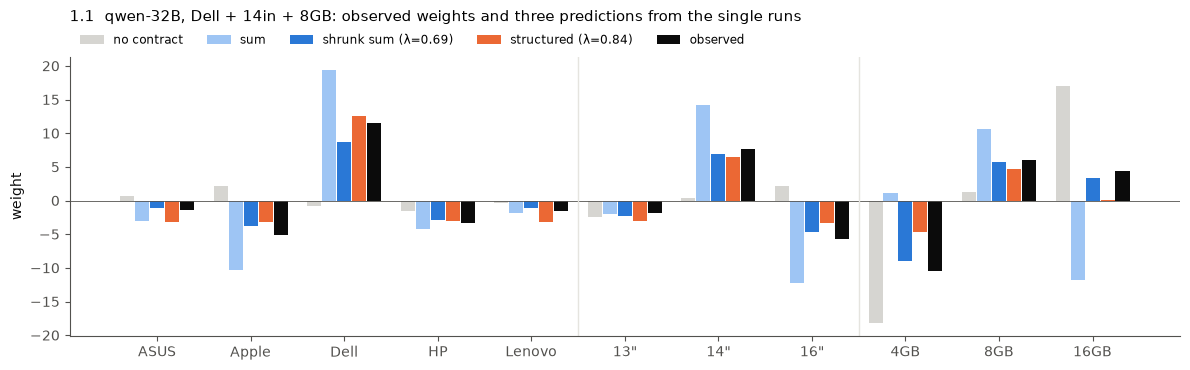

{'no contract': 0.664, 'sum': 0.696, 'shrunk sum (λ=0.69)': 0.932, 'structured (λ=0.84)': 0.821, 'observed': 0.952}


In [3]:
m, c = "qwen-32B", "brand=Dell+ram=8GB+screen=14-inch"; a, con = R[(m, "none")].w, parse(c)
lam_s, lam_t = fit_lam([x for x in COMP if x != (m, c)], "sum"), fit_lam([x for x in COMP if x != (m, c)], "struct")
EX = {"no contract": a, "sum": predict_sum(a, SING[m], con), f"shrunk sum (λ={lam_s:.2f})": predict_sum(a, SING[m], con, lam_s),
      f"structured (λ={lam_t:.2f})": predict_struct(a, P[m], con, lam_t), "observed": R[(m, c)].w}
fig, ax = plt.subplots(figsize=(12, 3.8)); x = np.arange(len(LV))
for k, ((name, w), col) in enumerate(zip(EX.items(), [LGRAY, "#9ec5f4", BLUE, ORANGE, INK])):
    ax.bar(x + (k - 2) * 0.16, w.values, 0.15, color=col, label=name)
ax.axhline(0, color=INK2, lw=0.6)
for b in (4.5, 7.5): ax.axvline(b, color=GRID, lw=1)
ax.set_xticks(x, [l.replace("-inch", '"') for _, l in LV]); ax.set_ylabel("weight")
ax.legend(frameon=False, ncol=5, fontsize=8.5, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title(f"1.1  {m}, {short(c)}: observed weights and three predictions from the single runs", loc="left", pad=26)
fig.tight_layout(); fig.savefig(f"{FIG}/04_1_example.png", dpi=150); plt.show()
print({k: round(pair_accuracy(additive_utility(w), R[(m, c)].D), 3) for k, w in EX.items()})

- **The plain sum overshoots**: it pushes Dell, 14-inch and 8GB further than the model does (pair accuracy 0.70).
- **Shrinking the sum by λ = 0.69 fixes it**: 0.93, close to the run's own weights (0.95). The structured rule,
  which uses only σ, ρ, κ per feature, gets 0.82.
- With no contract the model would get only 0.66 of the pairs right: the contract changes a third of its choices.

## 2. All compound runs: which rule predicts best?

Pair accuracy per compound run (dot), for each rule. λ leave-one-out. The oracle is the run's own weights (notebook 01).

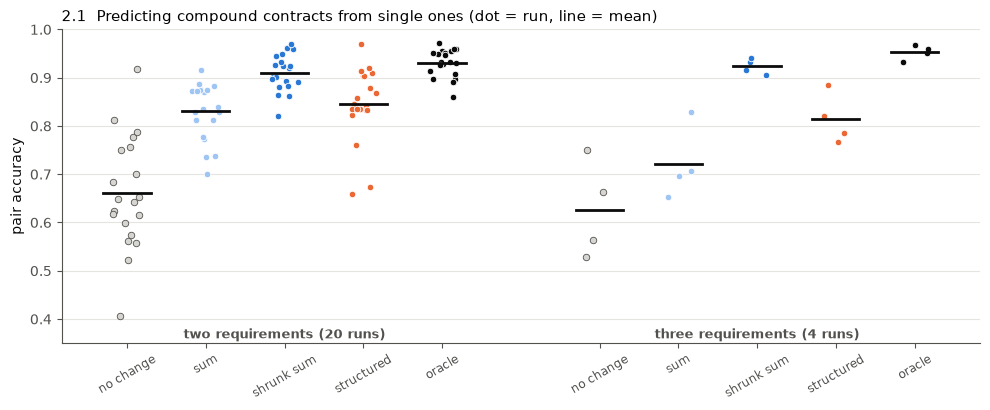

              acc           r2w       
q               2      3      2      3
pred                                  
no change   0.661  0.627 -0.323 -0.491
sum         0.830  0.721  0.644 -0.503
shrunk sum  0.910  0.924  0.947  0.923
structured  0.845  0.814  0.838  0.809
oracle      0.931  0.953  1.000  1.000


In [4]:
rows = []
for m, c in COMP:
    a, con, test = R[(m, "none")].w, parse(c), R[(m, c)]
    rest = [x for x in COMP if x != (m, c)]
    preds = {"no change": a}
    if all(k in SING[m] for k in con.items()):
        preds["sum"] = predict_sum(a, SING[m], con)
        preds["shrunk sum"] = predict_sum(a, SING[m], con, fit_lam([x for x in rest if all(k in SING[x[0]] for k in parse(x[1]).items())], "sum"))
    preds["structured"] = predict_struct(a, P[m], con, fit_lam(rest, "struct"))
    preds["oracle"] = test.w
    for name, wp in preds.items():
        rows.append(dict(model=m, c=c, q=len(con), pred=name, acc=pair_accuracy(additive_utility(wp), test.D), r2w=r2(wp.values, test.w.values)))
CP_ = pd.DataFrame(rows)
RULES = ["no change", "sum", "shrunk sum", "structured", "oracle"]; RC = [LGRAY, "#9ec5f4", BLUE, ORANGE, INK]
fig, ax = plt.subplots(figsize=(10, 4.2))
for k, (rname, col) in enumerate(zip(RULES, RC)):
    for qi, q in enumerate([2, 3]):
        s = CP_[(CP_.pred == rname) & (CP_.q == q)].acc
        xx = qi * 6 + k
        ax.scatter(np.full(len(s), xx) + np.random.default_rng(k).uniform(-0.18, 0.18, len(s)), s, s=22, color=col, edgecolor=INK2 if col == LGRAY else "white", linewidth=0.6, zorder=3)
        ax.plot([xx - 0.3, xx + 0.3], [s.mean()] * 2, color=INK, lw=2, zorder=4)
ax.set_xticks([qi * 6 + k for qi in range(2) for k in range(5)], RULES * 2, rotation=30, fontsize=8.5)
ax.text(2, 0.36, "two requirements (20 runs)", ha="center", fontsize=9.5, fontweight="bold", color=INK2)
ax.text(8, 0.36, "three requirements (4 runs)", ha="center", fontsize=9.5, fontweight="bold", color=INK2)
ax.set_ylim(0.35, 1.0); ax.set_ylabel("pair accuracy"); ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_title("2.1  Predicting compound contracts from single ones (dot = run, line = mean)", loc="left")
fig.tight_layout(); fig.savefig(f"{FIG}/04_2_rules.png", dpi=150); plt.show()
print(CP_.pivot_table(index="pred", columns="q", values=["acc", "r2w"]).reindex(RULES).round(3).to_string())

- **The shrunk sum is the best rule**: pair accuracy **0.91 / 0.92** for doubles / triples, against 0.93 / 0.95 for the
  oracle. On the weights, R² 0.95 / 0.92. One number (λ ≈ 0.69, fitted leave-one-out) is enough.
- **The plain sum overshoots**: 0.83 / 0.72, weight R² 0.64 / −0.50. Two requests together do less than the sum of each
  alone — the sub-additivity found in August, now on 24 runs.
- **The structured rule** (only σ, ρ, κ per feature, no single run needed): 0.85 / 0.81. Weaker, but it is the only
  rule that can predict a compound whose single parts were never run.
- "No change" gets 0.66 / 0.63: a compound contract changes about a third of the model's pair choices.

## 3. How much does each extra requirement shrink? The shape of λ

For every compound run, find the single factor *s* that best scales the plain sum to the observed shift
(*s* = 1: the sum is exact; *s* < 1: the requirements dilute each other). The formalization left two shapes open:
**λ^(q−1)** (each extra requirement multiplies by λ) and **q^(−α)** (a power law). With q = 2 only they are the same;
the 4 triple runs can now tell them apart.

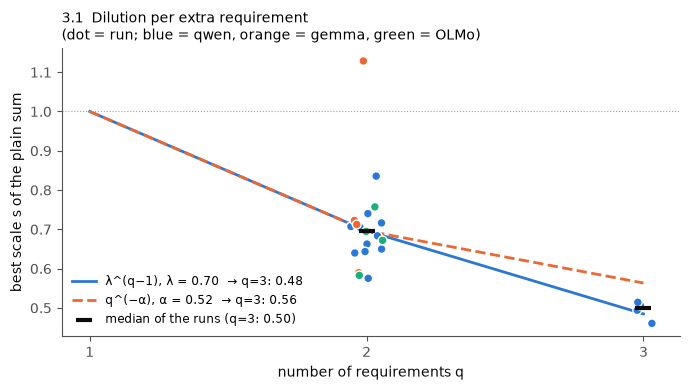

   count   mean    std    min    25%    50%    75%    max
q                                                        
2   20.0  0.706  0.117  0.575  0.648  0.696  0.718  1.129
3    4.0  0.494  0.024  0.461  0.486  0.500  0.508  0.514
       model                                   c  q      s
4   qwen-32B   brand=Dell+ram=8GB+screen=14-inch  3  0.494
7   qwen-72B   brand=Dell+ram=8GB+screen=14-inch  3  0.506
10  qwen-32B  brand=Apple+ram=8GB+screen=14-inch  3  0.461
12  qwen-32B   brand=Dell+ram=4GB+screen=14-inch  3  0.514


In [5]:
rows = []
for m, c in COMP:
    a, con = R[(m, "none")].w, parse(c)
    if not all(k in SING[m] for k in con.items()): continue
    H = predict_sum(a, SING[m], con) - a; S = R[(m, c)].w - a
    rows.append(dict(model=m, c=c, q=len(con), s=float(H @ S / (H @ H))))
SQ = pd.DataFrame(rows)
s2, s3 = SQ[SQ.q == 2].s.median(), SQ[SQ.q == 3].s.median()
alpha = -np.log(s2) / np.log(2)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(SQ.q + np.random.default_rng(1).uniform(-0.06, 0.06, len(SQ)), SQ.s, s=40, color=[FAMC[FAMILY[m]] for m in SQ.model], edgecolor="white", zorder=3)
qq = np.array([1, 2, 3])
ax.plot(qq, s2 ** (qq - 1), color=BLUE, lw=2, label=f"λ^(q−1), λ = {s2:.2f}  → q=3: {s2**2:.2f}")
ax.plot(qq, qq ** (-alpha), color=ORANGE, lw=2, ls="--", label=f"q^(−α), α = {alpha:.2f}  → q=3: {3**-alpha:.2f}")
ax.scatter([2, 3], [s2, s3], s=140, marker="_", color=INK, linewidth=3, zorder=4, label=f"median of the runs (q=3: {s3:.2f})")
ax.axhline(1, color=GRAY, lw=0.8, ls=":"); ax.set_xticks([1, 2, 3]); ax.set_xlabel("number of requirements q")
ax.set_ylabel("best scale s of the plain sum"); ax.legend(frameon=False, fontsize=8.5, loc="lower left")
ax.set_title("3.1  Dilution per extra requirement\n(dot = run; blue = qwen, orange = gemma, green = OLMo)", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(f"{FIG}/04_3_lambda_shape.png", dpi=150); plt.show()
print(SQ.groupby("q").s.describe().round(3).to_string())
print(SQ[SQ.q == 3].round(3).to_string())

- **Each extra requirement dilutes the push**: best scale of the plain sum **0.70** for doubles (0.58–1.13), **0.50** for
  triples (0.46–0.51).
- **λ^(q−1) fits the triples** (predicts 0.48, observed 0.50); the power law q^(−α) predicts 0.56. Each extra
  requirement multiplies the push by about the same λ ≈ 0.7.
- This **reverses** the answer of the CP version (before 11-03 the power law won, 0.63 vs 0.56 with observed 0.65).
  With 4 triple runs, all qwen, the shape is not settled; the gemma-27B triples (queued 11-02) are what decides it.

## 4. A bonus for meeting everything? (soft constraints)

The weight rules above are additive in the laptops: they cannot give an extra reward to the laptop that meets **all**
requirements at once. If the model treats the contract as one wish ("a Dell with a 14-inch screen"), that laptop should
score **above** what the shrunk sum predicts. Measure: per compound run, the observed utility minus the shrunk-sum
prediction (both centred), for the laptops that meet **all**, **some** or **none** of the requirements.

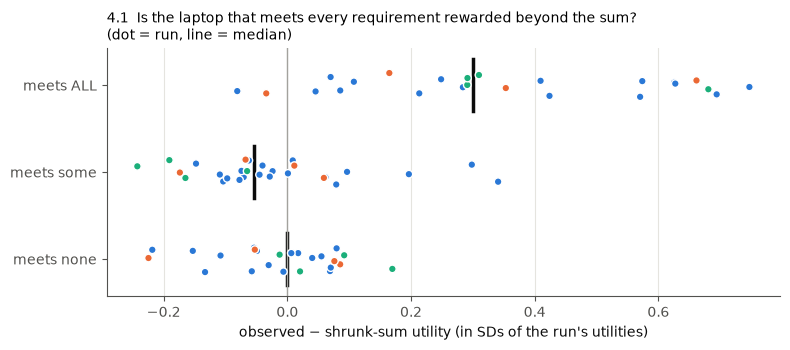

        count    50%    min    max
q met                             
2 all    20.0  0.287 -0.081  0.694
  none   20.0  0.013 -0.225  0.170
  some   20.0 -0.066 -0.243  0.097
3 all     4.0  0.626  0.571  0.747
  none    4.0 -0.101 -0.218  0.018
  some    8.0  0.040 -0.074  0.341


In [6]:
rows = []
for m, c in COMP:
    a, con = R[(m, "none")].w, parse(c)
    if not all(k in SING[m] for k in con.items()): continue
    lam = fit_lam([x for x in COMP if x != (m, c) and all(k in SING[x[0]] for k in parse(x[1]).items())], "sum")
    up = additive_utility(predict_sum(a, SING[m], con, lam)); uo = R[(m, c)].u
    scale = np.std(uo)
    res = ((uo - uo.mean()) - (up - up.mean())) / scale            # in SDs of the observed utility
    nmet = np.array([sum(l[FEATS.index(f)] == v for f, v in con.items()) for l in LAPTOPS])
    for k in range(len(con) + 1):
        rows.append(dict(model=m, c=c, q=len(con), met=("all" if k == len(con) else "none" if k == 0 else "some"), res=res[nmet == k].mean()))
BO = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, g in enumerate(["none", "some", "all"]):
    s = BO[BO.met == g]
    ax.scatter(s.res, np.full(len(s), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(s)), s=30,
               color=[FAMC[FAMILY[m]] for m in s.model], edgecolor="white", zorder=3)
    ax.plot([s.res.median()] * 2, [i - 0.3, i + 0.3], color=INK, lw=2.5)
ax.axvline(0, color=GRAY, lw=1); ax.set_yticks(range(3), ["meets none", "meets some", "meets ALL"])
ax.set_xlabel("observed − shrunk-sum utility (in SDs of the run's utilities)"); ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_title("4.1  Is the laptop that meets every requirement rewarded beyond the sum?\n(dot = run, line = median)", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(f"{FIG}/04_4_bonus.png", dpi=150); plt.show()
print(BO.groupby(["q", "met"]).res.describe()[["count", "50%", "min", "max"]].round(3).to_string())

- **There is a bonus for meeting everything.** The laptops that meet all requirements sit **above** the shrunk-sum
  prediction: median **+0.29 SD** for doubles (−0.08 … +0.69), **+0.63 SD** for triples (all 4 above +0.57). The ones
  that meet none or some sit at about 0.
- So the compound contract is partly read as **one wish** ("a Dell with a 14-inch screen and 8GB"), not only as a sum.
  The more requirements, the bigger the bonus.
- This reverses the CP version (before 11-03: −0.19 SD, "no bonus"). There, the residual mixed the interaction with the
  CP weights' error in size; with all-pairs weights the residual is only the part no sum of features can show.
- It fits notebook 05 §2b: meeting the request is a feature of its own, and missing it costs extra.

## Summary

| question | answer |
|---|---|
| can single runs predict compound contracts? | **yes**: shrunk sum, pair accuracy 0.91–0.92 vs ceiling 0.93–0.95 |
| how much does each extra requirement dilute? | ×0.70 for two, ×0.50 for three; λ^(q−1) fits (4 triples, qwen only) |
| a bonus for the laptop that meets all? | **yes** — +0.29 SD (two), +0.63 SD (three): an interaction the sum cannot show |
| what if the single parts were never run? | the structured rule (σ, ρ, κ) still gets 0.81–0.85 |

**For the sampling plan (formalization §8):** run every single request once, and **one** compound per model to fit the
dilution. The other compounds can be predicted at about 0.91 pair accuracy. A "meets all" bonus term would be the
first non-additive parameter worth adding.